<a href="https://colab.research.google.com/github/Alemisa/Machine-Learning_Practical-Sessions/blob/main/Lab03_Multi_LinearRegression_Model_Revenue_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**`2. Multiple-LinearRegression Model-01`**

Step-1: Import Necessary Labraries`

In [1]:
import pandas as pd

`Step-2: Import/loaad the dataset`

In [3]:
data=pd.read_csv("/content/House Price Prediction Dataset.csv")

`Step-3: Dataset description/ Quick data check`




In [4]:
data

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056
...,...,...,...,...,...,...,...,...,...,...
1995,1996,4994,5,4,3,1923,Suburban,Poor,No,295620
1996,1997,3046,5,2,1,2019,Suburban,Poor,Yes,580929
1997,1998,1062,5,1,2,1903,Rural,Poor,No,476925
1998,1999,4062,3,1,2,1936,Urban,Excellent,Yes,161119


In [5]:
data.head()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056


In [6]:
data.tail()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
1995,1996,4994,5,4,3,1923,Suburban,Poor,No,295620
1996,1997,3046,5,2,1,2019,Suburban,Poor,Yes,580929
1997,1998,1062,5,1,2,1903,Rural,Poor,No,476925
1998,1999,4062,3,1,2,1936,Urban,Excellent,Yes,161119
1999,2000,2989,5,1,3,1903,Suburban,Fair,No,482525


In [7]:
data.shape

(2000, 10)

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Id         2000 non-null   int64 
 1   Area       2000 non-null   int64 
 2   Bedrooms   2000 non-null   int64 
 3   Bathrooms  2000 non-null   int64 
 4   Floors     2000 non-null   int64 
 5   YearBuilt  2000 non-null   int64 
 6   Location   2000 non-null   object
 7   Condition  2000 non-null   object
 8   Garage     2000 non-null   object
 9   Price      2000 non-null   int64 
dtypes: int64(7), object(3)
memory usage: 156.4+ KB


In [9]:
data.describe()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price
count,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,1000.500000,2786.209500,3.003500,2.55250,1.993500,1961.446000,537676.855000
std,577.494589,1295.146799,1.424606,1.10899,0.809188,35.926695,276428.845719
min,1.000000,501.000000,1.000000,1.00000,1.000000,1900.000000,50005.000000
25%,500.750000,1653.000000,2.000000,2.00000,1.000000,1930.000000,300098.000000
50%,1000.500000,2833.000000,3.000000,3.00000,2.000000,1961.000000,539254.000000
75%,1500.250000,3887.500000,4.000000,4.00000,3.000000,1993.000000,780086.000000
max,2000.000000,4999.000000,5.000000,4.00000,3.000000,2023.000000,999656.000000


In [10]:
data.isna().sum()

,0
Id,0
Area,0
Bedrooms,0
Bathrooms,0
Floors,0
YearBuilt,0
Location,0
Condition,0
Garage,0
Price,0


In [11]:
data.isnull().count()

,0
Id,2000
Area,2000
Bedrooms,2000
Bathrooms,2000
Floors,2000
YearBuilt,2000
Location,2000
Condition,2000
Garage,2000
Price,2000


`Step-4: Define Features (X) and Target (y)`

In [12]:
X = data[['Area', 'Bedrooms', 'Bathrooms',
          'Floors', 'YearBuilt']]
y = data['Price']

`Step 5: Split Data into Train and Test Sets`

In [13]:
#Import labraries
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0)

* `Step 6: Build and Train the Multiple Linear Regression Model`

In [14]:
#Import Labraries
from sklearn.linear_model import LinearRegression
#Creating a Linear Regression Object
model=LinearRegression()
#Fitting the dataset #x needs to be 2D-arrays
#model.fit(x,y)
model.fit(X_train, y_train)

LinearRegression()

`Step 7: Check Regression Coefficients`

In [15]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})
print(coefficients)
print("Intercept:", model.intercept_)

     Feature   Coefficient
0       Area      2.914223
1   Bedrooms   1328.553496
2  Bathrooms  -2481.501331
3     Floors  16753.646179
4  YearBuilt     24.704286
Intercept: 447587.9030593077


`Step 8: Predict on Test Data`

In [16]:
y_pred = model.predict(X_test)

`Step 9: Evaluate Model Performance`

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
# 1. Mean Absolute Error (MAE)
mae = mean_absolute_error(y_test, y_pred)
# 2. Mean Squared Error (MSE)
mse = mean_squared_error(y_test, y_pred)
# 3. Root Mean Squared Error (RMSE)
rmse = np.sqrt(mse)
# 4. R-squared (Coefficient of Determination)
#R² Score (Goodness of Fit)
r2 = r2_score(y_test, y_pred)
# 5. Adjusted R-squared
n = len(y_test)           # number of observations
k = X_test.shape[1]       # number of features
adjusted_r2 = 1 - (1 - r2) * ((n - 1) / (n - k - 1))

# 6. Mean Absolute Percentage Error (MAPE)
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
# Print results
print("Model Evaluation Metrics:")
print("--------------------------")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse,  2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R-squared (R²):", round(r2,  3))
print("Adjusted R-squared:", round(adjusted_r2, 3))
print("Mean Absolute Percentage Error (MAPE):", round(mape,2), "%")


Model Evaluation Metrics:
--------------------------
Mean Absolute Error (MAE): 225345.43
Mean Squared Error (MSE): 69733125793.02
Root Mean Squared Error (RMSE): 264070.3
R-squared (R²): 0.003
Adjusted R-squared: -0.01
Mean Absolute Percentage Error (MAPE): 78.36 %


`Step 10: Visual Comparison (Actual vs Predicted)`

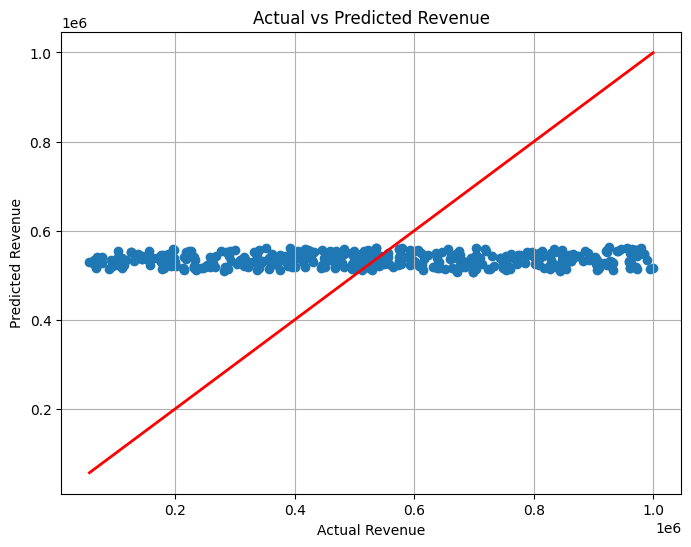

In [18]:
#Import labraries
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red', linewidth=2)
plt.xlabel("Actual Revenue")
plt.ylabel("Predicted Revenue")
plt.title("Actual vs Predicted Revenue")
plt.grid(True)
plt.show()

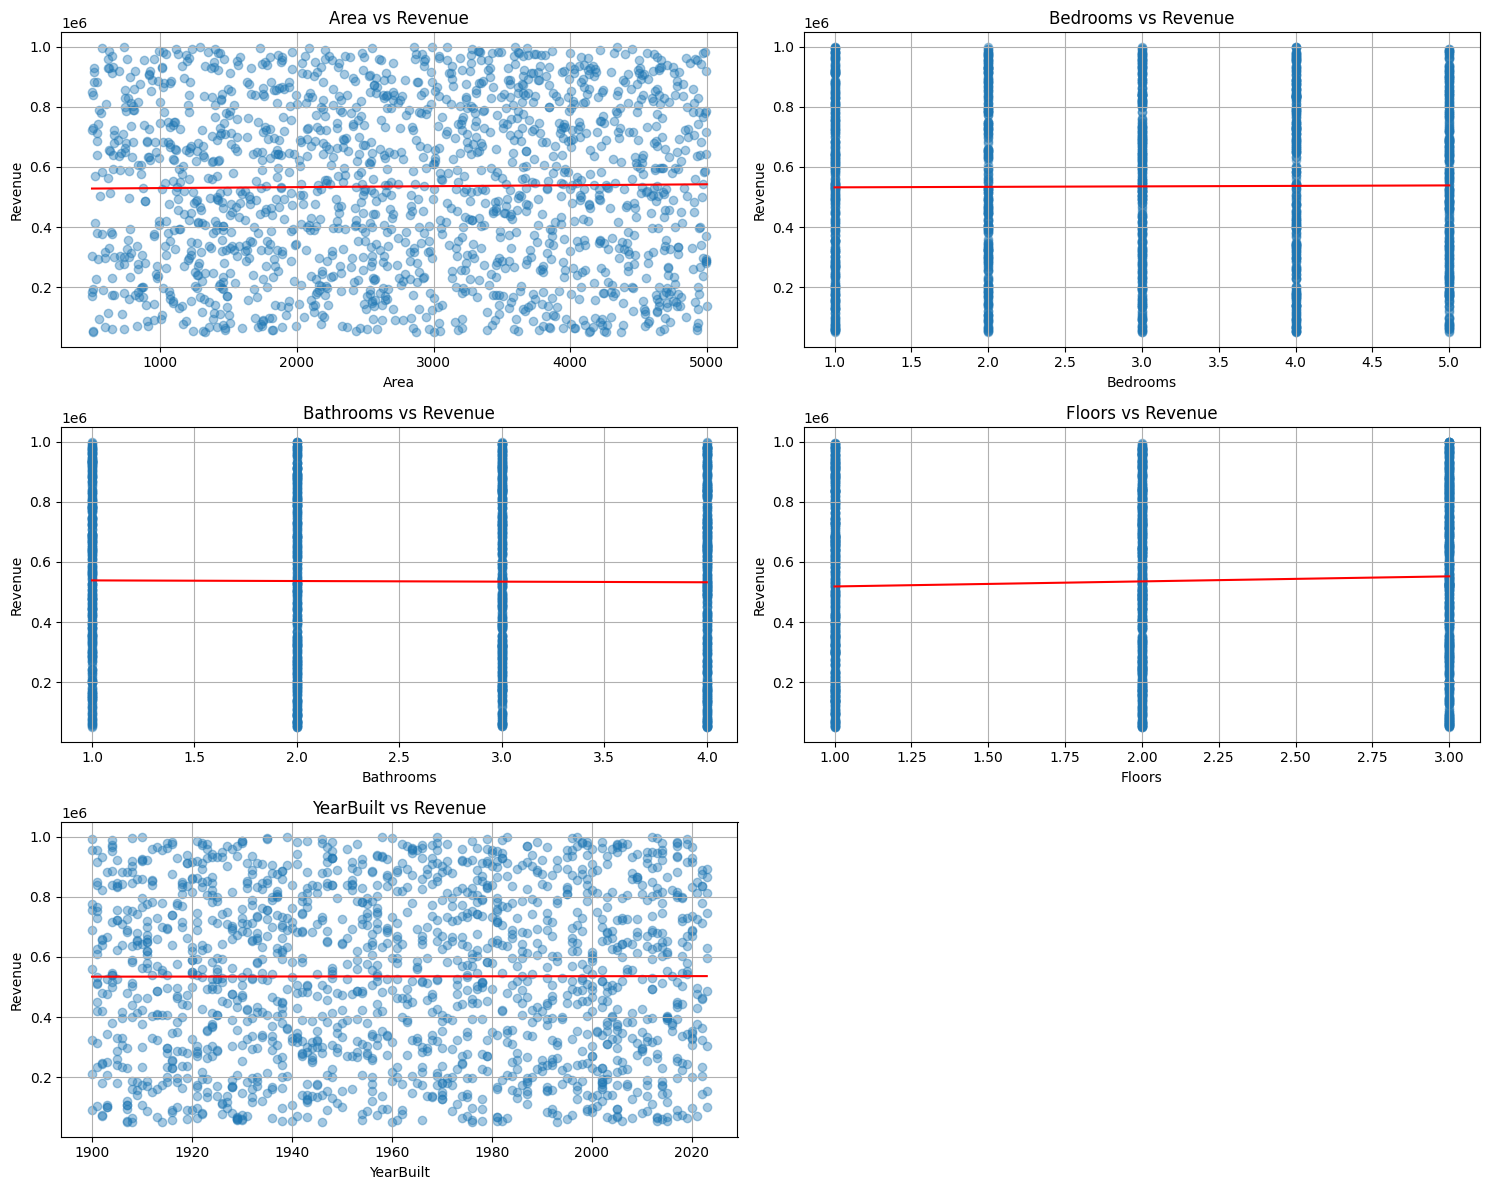

In [20]:
features = ['Area', 'Bedrooms', 'Bathrooms',
          'Floors', 'YearBuilt']

plt.figure(figsize=(15, 12))
for i, feature in enumerate(features, 1):
    plt.subplot(3, 2, i)
    x = X_train[feature]
    y = y_train
    model_single = LinearRegression()
    model_single.fit(x.values.reshape(-1, 1), y)
    x_line = np.linspace(x.min(), x.max(), 100).reshape(-1, 1)
    y_line = model_single.predict(x_line)
    plt.scatter(x, y, alpha=0.4)
    plt.plot(x_line, y_line, color="red")
    plt.title(f'{feature} vs Revenue')
    plt.xlabel(feature)
    plt.ylabel("Revenue")
    plt.grid(True)
plt.tight_layout()
plt.show()


`Step 11: Predict Revenue for New Input Values`

In [26]:
new_data = pd.DataFrame({
    'Area': [45000],
    'Bedrooms': [3500],
    'Bathrooms': [9000],
    'Floors': [15000],
    'YearBuilt': [120000]
})
predicted_price = model.predict(new_data)
print("Predicted Monthly house price:", predicted_revenue[0])

Predicted Monthly house price: 237164360.19826213


In [27]:
#rounded output:
print("Predicted Monthly House price:", round(predicted_price[0], 2))

Predicted Monthly House price: 237164360.2
